In [1]:
import re
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel, pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from datasets import load_dataset

# Load tokenizer and model
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModel.from_pretrained("bert-base-uncased").eval()

c:\Users\Ruda\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Ruda\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Ruda\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administra

In [2]:
# 1. Tokenization
sentences_t1 = [
    "Hello, this is Bert.",
    "Tokenization of unbelievably long words."
]

for s in sentences_t1:
    ids = tok(s)["input_ids"]
    tokens = tok.convert_ids_to_tokens(ids)
    special = [t for t in tokens if t in tok.all_special_tokens]
    subwords = [t for t in tokens if t.startswith("##")]
    
    print(f"Sentence: {s}")
    print(f"  Tokens ({len(tokens)}): {tokens}")
    print(f"  Special tokens: {special}")
    print(f"  Subword pieces (##): {subwords}\n")

# 2. Masked word prediction
unmasker = pipeline("fill-mask", model="bert-base-uncased")

masked_sentences = [
    "The cat sat on the [MASK].",
    "Paris is the capital of [MASK].",
    "I went to the [MASK] to withdraw some money.",
    "The man worked as a [MASK].",
    "The woman worked as a [MASK]."
]

for s in masked_sentences:
    preds = unmasker(s, top_k=5)
    top5 = ", ".join([f"{p['token_str']} ({p['score']:.2f})" for p in preds])
    print(f"{s}\n  -> {top5}\n")

Sentence: Hello, this is Bert.
  Tokens (8): ['[CLS]', 'hello', ',', 'this', 'is', 'bert', '.', '[SEP]']
  Special tokens: ['[CLS]', '[SEP]']
  Subword pieces (##): []

Sentence: Tokenization of unbelievably long words.
  Tokens (13): ['[CLS]', 'token', '##ization', 'of', 'un', '##bel', '##ie', '##va', '##bly', 'long', 'words', '.', '[SEP]']
  Special tokens: ['[CLS]', '[SEP]']
  Subword pieces (##): ['##ization', '##bel', '##ie', '##va', '##bly']



Loading weights: 100%|██████████| 202/202 [00:00<00:00, 720.77it/s]
[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


The cat sat on the [MASK].
  -> floor (0.31), bed (0.12), couch (0.11), sofa (0.06), ground (0.06)

Paris is the capital of [MASK].
  -> france (0.95), algeria (0.01), morocco (0.00), reunion (0.00), haiti (0.00)

I went to the [MASK] to withdraw some money.
  -> bank (0.96), store (0.01), banks (0.00), atm (0.00), office (0.00)

The man worked as a [MASK].
  -> carpenter (0.10), waiter (0.05), barber (0.05), mechanic (0.04), salesman (0.04)

The woman worked as a [MASK].
  -> nurse (0.22), waitress (0.16), maid (0.12), prostitute (0.04), cook (0.03)



Cosine similarity matrix (Layer 12):
[[1.   0.8  0.79 0.54 0.42 0.44]
 [0.8  1.   0.81 0.48 0.42 0.41]
 [0.79 0.81 1.   0.49 0.44 0.46]
 [0.54 0.48 0.49 1.   0.83 0.74]
 [0.42 0.42 0.44 0.83 1.   0.71]
 [0.44 0.41 0.46 0.74 0.71 1.  ]]
Layer  0: same = 0.96, diff = 0.97
Layer  6: same = 0.80, diff = 0.52
Layer 12: same = 0.78, diff = 0.46


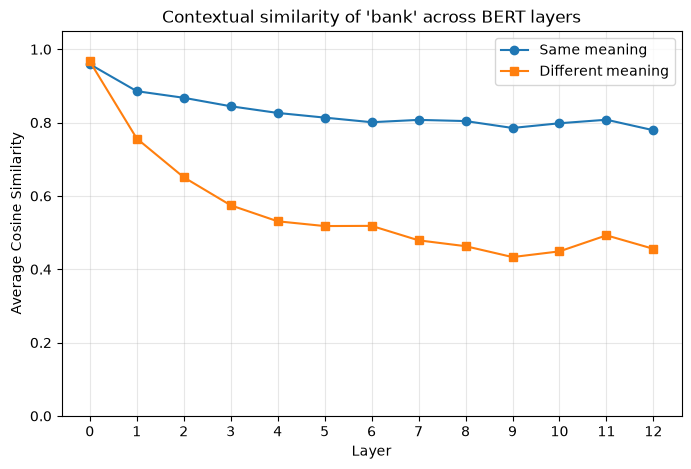

In [3]:
sentences_t2 = [
    "We sat on the bank of the river.",
    "The boat drifted to the muddy bank.",
    "Fishermen stood on the river bank.",     # river bank (0, 1, 2)
    "I deposited money at the bank.",
    "The bank approved my loan.",
    "She works at a bank in Prague."          # financial bank (3, 4, 5)
]

bank_id = tok.convert_tokens_to_ids("bank")

# Extract embeddings for "bank" across all 13 layers (0..12)
layer_embs = [[] for _ in range(13)]

with torch.no_grad():
    for s in sentences_t2:
        inputs = tok(s, return_tensors="pt")
        out = model(**inputs, output_hidden_states=True)
        
        # Find token position of "bank"
        pos = (inputs["input_ids"][0] == bank_id).nonzero(as_tuple=True)[0][0].item()
        
        for layer in range(13):
            vec = out.hidden_states[layer][0, pos].numpy()
            layer_embs[layer].append(vec)

layer_embs = [np.array(embs) for embs in layer_embs]

# Helper for cosine similarity matrix
def cosine_sim_matrix(X):
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    X_norm = X / norms
    return X_norm @ X_norm.T

# Print 6x6 cosine similarity matrix for the last layer (layer 12)
sim_last = cosine_sim_matrix(layer_embs[12])
print("Cosine similarity matrix (Layer 12):")
print(np.round(sim_last, 2))

# Average similarity for same vs. different meaning across layers 0..12
same_sims = []
diff_sims = []

for layer in range(13):
    S = cosine_sim_matrix(layer_embs[layer])
    
    # Same meaning pairs: within (0,1,2) and within (3,4,5), excluding diagonal
    same_pairs = [S[i, j] for i in range(3) for j in range(i + 1, 3)] + \
                 [S[i, j] for i in range(3, 6) for j in range(i + 1, 6)]
    
    # Different meaning pairs: (0,1,2) vs (3,4,5)
    diff_pairs = [S[i, j] for i in range(3) for j in range(3, 6)]
    
    same_sims.append(np.mean(same_pairs))
    diff_sims.append(np.mean(diff_pairs))

for l in [0, 6, 12]:
    print(f"Layer {l:2d}: same = {same_sims[l]:.2f}, diff = {diff_sims[l]:.2f}")

# Plot layer similarities
plt.figure(figsize=(8, 5))
plt.plot(range(13), same_sims, marker="o", label="Same meaning")
plt.plot(range(13), diff_sims, marker="s", label="Different meaning")
plt.xlabel("Layer")
plt.ylabel("Average Cosine Similarity")
plt.title("Contextual similarity of 'bank' across BERT layers")
plt.xticks(range(13))
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [4]:
# Load Simple Wikipedia and filter sentences containing "bank"
wiki = load_dataset("wikimedia/wikipedia", "20231101.simple", split="train")
wiki_sents = set()

for text in wiki["text"]:
    if "bank" not in text.lower():
        continue
    for s in re.split(r"(?<=[.!?])\s+", text.replace("\n", " ")):
        if re.search(r"\bbank\b", s.lower()) and 6 <= len(s.split()) <= 40:
            wiki_sents.add(s.strip())

wiki_sents = sorted(wiki_sents)

# Compute embeddings in batches (average of last 4 layers)
batch_size = 64
valid_sents = []
valid_embs = []

with torch.no_grad():
    for i in range(0, len(wiki_sents), batch_size):
        batch = wiki_sents[i:i + batch_size]
        inputs = tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=128)
        out = model(**inputs, output_hidden_states=True)
        
        # Average of last 4 hidden layers -> shape (B, L, 768)
        last4 = torch.stack(out.hidden_states[-4:], dim=0).mean(dim=0)
        
        for j, sent in enumerate(batch):
            positions = (inputs["input_ids"][j] == bank_id).nonzero(as_tuple=True)[0]
            if len(positions) == 0:
                continue  # Skip if "bank" is not a standalone token
            pos = positions[0].item()
            valid_sents.append(sent)
            valid_embs.append(last4[j, pos].numpy())

X_wiki = np.array(valid_embs)
print(f"Sentences with standalone token 'bank': {len(valid_sents)}")

Sentences with standalone token 'bank': 3410


In [5]:
# Custom K-means from previous exercises
def kmeans(X, K, rng, tol=1e-6, max_iter=300):
    init_indices = rng.choice(len(X), size=K, replace=False)
    centroids = X[init_indices].copy()
    j_history = []
    
    for _ in range(max_iter):
        dists = np.sum((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)
        labels = np.argmin(dists, axis=1)
        J = np.sum(np.min(dists, axis=1))
        j_history.append(J)
        
        if len(j_history) > 1 and (j_history[-2] - J) < tol:
            break
            
        new_centroids = np.zeros_like(centroids)
        for k in range(K):
            mask = (labels == k)
            new_centroids[k] = X[mask].mean(axis=0) if np.any(mask) else centroids[k]
        centroids = new_centroids
        
    return labels, centroids, j_history

# Run K-means 10 times (K=3) and pick best
rng = np.random.default_rng(0)
best_J = float("inf")
best_labels, best_centroids = None, None

for _ in range(10):
    labels, centroids, j_hist = kmeans(X_wiki, 3, rng)
    if j_hist[-1] < best_J:
        best_J = j_hist[-1]
        best_labels, best_centroids = labels, centroids

# Extract 8 typical words per cluster using CountVectorizer
vec = CountVectorizer(stop_words="english", min_df=5, binary=True)
dtm = vec.fit_transform(valid_sents).toarray()
vocab = np.array(vec.get_feature_names_out())
global_freq = dtm.mean(axis=0)

for k in range(3):
    mask = (best_labels == k)
    cluster_freq = dtm[mask].mean(axis=0)
    # Words most distinctive for this cluster compared to the rest
    top_idx = np.argsort(cluster_freq - global_freq)[::-1][:8]
    print(f"Cluster {k} ({mask.sum()} sentences): {vocab[top_idx].tolist()}")

Cluster 0 (499 sentences): ['west', 'money', 'israel', 'match', 'gaza', 'strip', 'ladder', 'wwe']
Cluster 1 (556 sentences): ['river', 'left', 'north', 'south', 'right', 'east', 'located', 'city']
Cluster 2 (2355 sentences): ['world', 'central', 'president', 'national', 'united', 'banks', 'states', 'financial']


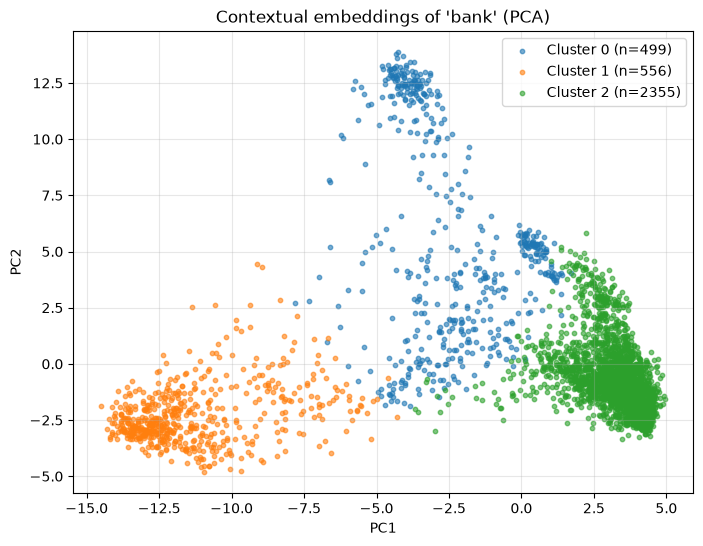

In [6]:
pca = PCA(n_components=2, random_state=0)
X_2d = pca.fit_transform(X_wiki)

plt.figure(figsize=(8, 6))
for k in range(3):
    mask = (best_labels == k)
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1], s=10, alpha=0.6, label=f"Cluster {k} (n={mask.sum()})")

plt.title("Contextual embeddings of 'bank' (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
new_sents = [
    "We had a picnic on the bank of the lake.",
    "The bank raised interest rates again.",
    "Settlers moved into the West Bank.",
    "The plane had to bank sharply to the left."
]

with torch.no_grad():
    inputs = tok(new_sents, return_tensors="pt", padding=True, truncation=True, max_length=128)
    out = model(**inputs, output_hidden_states=True)
    last4 = torch.stack(out.hidden_states[-4:], dim=0).mean(dim=0)

    for j, s in enumerate(new_sents):
        pos = (inputs["input_ids"][j] == bank_id).nonzero(as_tuple=True)[0][0].item()
        emb = last4[j, pos].numpy()
        
        # Euclidean distances to all 3 centroids
        dists = np.linalg.norm(best_centroids - emb, axis=1)
        nearest = np.argmin(dists)
        print(f"'{s}'")
        print(f"  -> Cluster {nearest} | distances: {np.round(dists, 2).tolist()}\n")

'We had a picnic on the bank of the lake.'
  -> Cluster 1 | distances: [15.890000343322754, 11.5, 17.31999969482422]

'The bank raised interest rates again.'
  -> Cluster 2 | distances: [12.40999984741211, 16.540000915527344, 7.46999979019165]

'Settlers moved into the West Bank.'
  -> Cluster 0 | distances: [9.779999732971191, 15.8100004196167, 15.09000015258789]

'The plane had to bank sharply to the left.'
  -> Cluster 0 | distances: [17.09000015258789, 18.489999771118164, 18.030000686645508]

